
###Fraud Detection & Financial Risk Analytics Using Machine Learning
###Background

Financial fraud has become an important challenge for businesses that process large volumes of digital transactions. As online payments continue to grow, organizations need reliable ways to identify suspicious transactions while allowing legitimate transactions to go through without unnecessary disruption.

This project uses transaction and identity data to explore patterns associated with fraudulent activity and develop a machinelearning approach for identifying potentially fraudulent transactions. Beyond simply predicting whether a transaction is fraudulent the project focuses on understanding fraud patterns, managing the challenges of imbalanced data and translating model predictions into actionable financial risk insights.


###Research Question
###Main research question
How can transaction and identity data be used to identify potentially fraudulent transactions and support more effective financial risk management?

Supporting questions
1. What transaction and identity characteristics are associated with fraudulent activity?
2. How does fraudulent transaction behaviour differ from legitimate transaction behaviour?
3. Which features contribute most to identifying potentially fraudulent transactions?
4. How effectively can machine learning models distinguish fraudulent transactions from legitimate ones?
5. Which evaluation metrics are most appropriate for assessing fraud detection when fraudulent transactions are relatively uncommon?
6. How can model predictions be translated into practical fraud risk insights for financial businesses?

###General Objective
To develop a data driven fraud detection and financial risk analytics system that identifies potentially fraudulent transactions and provides actionable insights for reducing financial risk.

Specific Objectives
1. To explore transaction and identity data to identify patterns and characteristics associated with fraudulent activity.
2. To use SQL to combine, query and transform transaction and identity data into an analytical dataset.
3. To perform data cleaning and feature engineering to create meaningful variables for fraud detection.
4. To develop and compare machine-learning models for identifying fraudulent transactions, including a baseline model and more advanced approaches.
5. To address class imbalance and evaluate model performance using appropriate metrics such as precision, recall, F1-score, ROC-AUC and PR-AUC.
6. To identify important fraud risk factors and interpret the model's findings from a business perspective.
7. To develop a risk-scoring approach that can categorize transactions according to their potential fraud risk.
8. To present the findings through an interactive dashboard that communicates fraud patterns, model performance and financial-risk insights.

In [1]:

import os
import pandas as pd
import numpy as np

# Define project paths
PROJECT_PATH = "/content/drive/MyDrive/fraud detection project"
RAW_PATH = os.path.join(PROJECT_PATH, "data", "raw")

# Check that the data folder exists
print("Project path:", PROJECT_PATH)
print("Raw data path:", RAW_PATH)

# List files in the raw data folder
print("\nFiles available:")
for file in os.listdir(RAW_PATH):
    print("-", file)

Project path: /content/drive/MyDrive/fraud detection project
Raw data path: /content/drive/MyDrive/fraud detection project/data/raw

Files available:
- test_identity.csv
- test_transaction.csv
- train_identity.csv
- train_transaction.csv


In [2]:
import pandas as pd
import os
# Define file paths
TRAIN_TRANSACTION = os.path.join(RAW_PATH, "train_transaction.csv")
TRAIN_IDENTITY = os.path.join(RAW_PATH, "train_identity.csv")
TEST_TRANSACTION = os.path.join(RAW_PATH, "test_transaction.csv")
TEST_IDENTITY = os.path.join(RAW_PATH, "test_identity.csv")
# Load datasets
train_transaction = pd.read_csv(TRAIN_TRANSACTION)
train_identity = pd.read_csv(TRAIN_IDENTITY)
test_transaction = pd.read_csv(TEST_TRANSACTION)
test_identity = pd.read_csv(TEST_IDENTITY)
# Check the data
print("Train transaction shape:", train_transaction.shape)
print("Train identity shape:", train_identity.shape)
print("Test transaction shape:", test_transaction.shape)
print("Test identity shape:", test_identity.shape)

Train transaction shape: (590540, 394)
Train identity shape: (144233, 41)
Test transaction shape: (506691, 393)
Test identity shape: (141907, 41)


In [3]:
# Check the first few rows
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
train_transaction.isnull().sum().head(20)

,0
TransactionID,0
isFraud,0
TransactionDT,0
TransactionAmt,0
ProductCD,0
card1,0
card2,8933
card3,1565
card4,1577
card5,4259


In [5]:
train_transaction["isFraud"].value_counts()

,count
isFraud,
0,569877
1,20663


In [6]:
#basic data cleaning
# Check for duplicate transactions
print("Duplicate rows:", train_transaction.duplicated().sum())

Duplicate rows: 0


In [7]:
# Check for missing values
missing_values = train_transaction.isnull().sum()
print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
card2      8933
card3      1565
card4      1577
card5      4259
card6      1571
          ...  
V335     508189
V336     508189
V337     508189
V338     508189
V339     508189
Length: 374, dtype: int64


In [8]:
# Check the percentage of missing values
missing_percent = train_transaction.isnull().mean() * 100
print("Columns with more than 50% missing values:")
print(missing_percent[missing_percent > 50])

Columns with more than 50% missing values:
dist1            59.652352
dist2            93.628374
R_emaildomain    76.751617
D5               52.467403
D6               87.606767
                   ...    
V335             86.054967
V336             86.054967
V337             86.054967
V338             86.054967
V339             86.054967
Length: 174, dtype: float64


In [9]:
# Remove columns with more than 50% missing values
train_transaction = train_transaction.loc[:, missing_percent <= 50]
print("New train transaction shape:", train_transaction.shape)

New train transaction shape: (590540, 220)


In [10]:
# Fill missing values in numeric columns with the median
numeric_columns = train_transaction.select_dtypes(include='number').columns
train_transaction[numeric_columns] = train_transaction[numeric_columns].fillna(
    train_transaction[numeric_columns].median())
print("Missing values after cleaning:")
print(train_transaction.isnull().sum().sum())

Missing values after cleaning:
1361708


In [11]:
# Check missing values in all datasets
print("Train transaction missing values:", train_transaction.isnull().sum().sum())
print("Train identity missing values:", train_identity.isnull().sum().sum())
print("Test transaction missing values:", test_transaction.isnull().sum().sum())
print("Test identity missing values:", test_identity.isnull().sum().sum())

Train transaction missing values: 1361708
Train identity missing values: 2104107
Test transaction missing values: 73490163
Test identity missing values: 2105385


In [12]:
# Combine training transaction and identity data
train_data = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left")
print("Train data shape:", train_data.shape)

Train data shape: (590540, 260)


In [13]:
# Check the fraud distribution
print(train_data["isFraud"].value_counts())

isFraud
0    569877
1     20663
Name: count, dtype: int64


In [14]:
# Check data types in the combined training data
print("Numeric columns:", train_data.select_dtypes(include='number').shape[1])
print("Categorical columns:", train_data.select_dtypes(exclude='number').shape[1])
# Check remaining missing values
missing_train = train_data.isnull().sum()
print("Columns with missing values:")
print(missing_train[missing_train > 0].sort_values(ascending=False).head(20))

Numeric columns: 234
Categorical columns: 26
Columns with missing values:
id_24         585793
id_25         585408
id_08         585385
id_07         585385
id_21         585381
id_26         585377
id_27         585371
id_22         585371
id_23         585371
id_18         545427
id_03         524216
id_04         524216
id_33         517251
id_09         515614
id_10         515614
id_30         512975
id_32         512954
id_34         512735
id_14         510496
DeviceInfo    471874
dtype: int64


In [15]:
# Fill missing values in categorical columns with "Unknown"
categorical_columns = train_data.select_dtypes(exclude='number').columns
train_data[categorical_columns] = train_data[categorical_columns].fillna("Unknown")
print("Missing values after filling categorical columns:")
print(train_data.isnull().sum().sum())

Missing values after filling categorical columns:
11816416


In [16]:
# Fill remaining missing values in numeric columns with the median

numeric_columns = train_data.select_dtypes(include='number').columns
train_data[numeric_columns] = train_data[numeric_columns].fillna(
    train_data[numeric_columns].median())
print("Missing values after complete cleaning:")
print(train_data.isnull().sum().sum())

Missing values after complete cleaning:
0


In [17]:
# Check for duplicate rows after merging and cleaning
duplicates = train_data.duplicated().sum()
print("Duplicate rows after cleaning:", duplicates)

Duplicate rows after cleaning: 0


In [18]:
# connecting train data to DuckDB
#Install DuckDB
!pip install duckdb -q
import duckdb
# Register the cleaned train_data DataFrame as a SQL table
duckdb.register("train_data", train_data)
print("SQL connection successful!")

SQL connection successful!


In [19]:
#total number of transactions and fraud cases
query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraudulent_transactions,
    SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END) AS non_fraudulent_transactions
FROM train_data """
result = duckdb.sql(query)
print(result)

┌────────────────────┬─────────────────────────┬─────────────────────────────┐
│ total_transactions │ fraudulent_transactions │ non_fraudulent_transactions │
│       int64        │         int128          │           int128            │
├────────────────────┼─────────────────────────┼─────────────────────────────┤
│             590540 │                   20663 │                      569877 │
└────────────────────┴─────────────────────────┴─────────────────────────────┘



In [20]:
#calculating the overal fraud rate
query = """
SELECT
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 2) AS fraud_rate_percentage
FROM train_data
"""
print(duckdb.sql(query))

┌───────────────────────┐
│ fraud_rate_percentage │
│        double         │
├───────────────────────┤
│                   3.5 │
└───────────────────────┘



In [21]:
#fraud by transaction type
query = """
SELECT
    ProductCD,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraudulent_transactions,
    ROUND(100.0 * SUM(isFraud) / COUNT(*), 2) AS fraud_rate_percentage
FROM train_data
GROUP BY ProductCD
ORDER BY fraud_rate_percentage DESC """
print(duckdb.sql(query))

┌───────────┬────────────────────┬─────────────────────────┬───────────────────────┐
│ ProductCD │ total_transactions │ fraudulent_transactions │ fraud_rate_percentage │
│  varchar  │       int64        │         int128          │        double         │
├───────────┼────────────────────┼─────────────────────────┼───────────────────────┤
│ C         │              68519 │                    8008 │                 11.69 │
│ S         │              11628 │                     686 │                   5.9 │
│ H         │              33024 │                    1574 │                  4.77 │
│ R         │              37699 │                    1426 │                  3.78 │
│ W         │             439670 │                    8969 │                  2.04 │
└───────────┴────────────────────┴─────────────────────────┴───────────────────────┘



In [22]:

# Fraud analysis by transaction amount

query = """
SELECT
    CASE
        WHEN TransactionAmt < 50 THEN 'Below 50'
        WHEN TransactionAmt < 100 THEN '50 - 99'
        WHEN TransactionAmt < 500 THEN '100 - 499'
        WHEN TransactionAmt < 1000 THEN '500 - 999'
        ELSE '1000+'
    END AS amount_range,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraudulent_transactions,
    ROUND(
        100.0 * SUM(isFraud) / COUNT(*),
        2
    ) AS fraud_rate_percentage
FROM train_data
GROUP BY amount_range
ORDER BY fraud_rate_percentage DESC """
print(duckdb.sql(query))

┌──────────────┬────────────────────┬─────────────────────────┬───────────────────────┐
│ amount_range │ total_transactions │ fraudulent_transactions │ fraud_rate_percentage │
│   varchar    │       int64        │         int128          │        double         │
├──────────────┼────────────────────┼─────────────────────────┼───────────────────────┤
│ 500 - 999    │              16744 │                     962 │                  5.75 │
│ Below 50     │             187515 │                    7480 │                  3.99 │
│ 100 - 499    │             217959 │                    7416 │                   3.4 │
│ 50 - 99      │             160742 │                    4618 │                  2.87 │
│ 1000+        │               7580 │                     187 │                  2.47 │
└──────────────┴────────────────────┴─────────────────────────┴───────────────────────┘



In [23]:
#fraud by transactional type
# Fraud analysis by card type
query = """
SELECT
    card4,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraudulent_transactions,
    ROUND(
        100.0 * SUM(isFraud) / COUNT(*),
        2
    ) AS fraud_rate_percentage
FROM train_data
WHERE card4 IS NOT NULL
GROUP BY card4
ORDER BY fraud_rate_percentage DESC """
print(duckdb.sql(query))

┌──────────────────┬────────────────────┬─────────────────────────┬───────────────────────┐
│      card4       │ total_transactions │ fraudulent_transactions │ fraud_rate_percentage │
│     varchar      │       int64        │         int128          │        double         │
├──────────────────┼────────────────────┼─────────────────────────┼───────────────────────┤
│ discover         │               6651 │                     514 │                  7.73 │
│ visa             │             384767 │                   13373 │                  3.48 │
│ mastercard       │             189217 │                    6496 │                  3.43 │
│ american express │               8328 │                     239 │                  2.87 │
│ Unknown          │               1577 │                      41 │                   2.6 │
└──────────────────┴────────────────────┴─────────────────────────┴───────────────────────┘



In [24]:
# Fraud rate by product and card type

query = """
SELECT
    ProductCD,
    card4,
    COUNT(*) AS total_transactions,
    SUM(isFraud) AS fraudulent_transactions,
    ROUND(
        100.0 * SUM(isFraud) / COUNT(*),
        2
    ) AS fraud_rate_percentage
FROM train_data
WHERE card4 IS NOT NULL
GROUP BY ProductCD, card4
HAVING COUNT(*) >= 100
ORDER BY fraud_rate_percentage DESC"""
print(duckdb.sql(query))

┌───────────┬──────────────────┬────────────────────┬─────────────────────────┬───────────────────────┐
│ ProductCD │      card4       │ total_transactions │ fraudulent_transactions │ fraud_rate_percentage │
│  varchar  │     varchar      │       int64        │         int128          │        double         │
├───────────┼──────────────────┼────────────────────┼─────────────────────────┼───────────────────────┤
│ S         │ discover         │                580 │                      77 │                 13.28 │
│ C         │ visa             │              40904 │                    4916 │                 12.02 │
│ C         │ mastercard       │              27418 │                    3072 │                  11.2 │
│ C         │ Unknown          │                195 │                      18 │                  9.23 │
│ W         │ discover         │               4379 │                     336 │                  7.67 │
│ H         │ discover         │                603 │           

In [25]:
#FEATURE ENGINEERING
#Transaction Amount features
import numpy as np
# Log transformation of transaction amount
train_data["TransactionAmt_log"] = np.log1p(train_data["TransactionAmt"])
# Transaction amount rounded
train_data["TransactionAmt_rounded"] = train_data["TransactionAmt"].round()
print("Transaction amount features created.")
print(train_data[[
    "TransactionAmt",
    "TransactionAmt_log",
    "TransactionAmt_rounded"
]].head())

Transaction amount features created.
   TransactionAmt  TransactionAmt_log  TransactionAmt_rounded
0            68.5            4.241327                    68.0
1            29.0            3.401197                    29.0
2            59.0            4.094345                    59.0
3            50.0            3.931826                    50.0
4            50.0            3.931826                    50.0


/tmp/ipykernel_1661/218186715.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["TransactionAmt_log"] = np.log1p(train_data["TransactionAmt"])
/tmp/ipykernel_1661/218186715.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["TransactionAmt_rounded"] = train_data["TransactionAmt"].round()


In [26]:
#create time based feature
#Time Features

train_data["Transaction_hour"] = ((train_data["TransactionDT"] // 3600) % 24)
train_data["Transaction_day"] = (train_data["TransactionDT"] // (3600 * 24))
train_data["Transaction_week"] = (train_data["Transaction_day"] // 7)

print("Time-based features created.")
print(train_data[[
    "TransactionDT",
    "Transaction_hour",
    "Transaction_day",
    "Transaction_week"
]].head())

Time-based features created.
   TransactionDT  Transaction_hour  Transaction_day  Transaction_week
0          86400                 0                1                 0
1          86401                 0                1                 0
2          86469                 0                1                 0
3          86499                 0                1                 0
4          86506                 0                1                 0


/tmp/ipykernel_1661/2585373569.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["Transaction_hour"] = ((train_data["TransactionDT"] // 3600) % 24)
/tmp/ipykernel_1661/2585373569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["Transaction_day"] = (train_data["TransactionDT"] // (3600 * 24))
/tmp/ipykernel_1661/2585373569.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns 

In [27]:
# Card Features
train_data["card1_card2"] = (
    train_data["card1"].astype(str) + "_" +
    train_data["card2"].astype(str))

train_data["card1_card3"] = (
    train_data["card1"].astype(str) + "_" +
    train_data["card3"].astype(str))

train_data["card1_card5"] = (
    train_data["card1"].astype(str) + "_" +
    train_data["card5"].astype(str))
print("Card interaction features created.")

/tmp/ipykernel_1661/467133499.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["card1_card2"] = (
/tmp/ipykernel_1661/467133499.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["card1_card3"] = (


Card interaction features created.


/tmp/ipykernel_1661/467133499.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["card1_card5"] = (


In [28]:
#Create amount-per-installment type features
#Amount Relationships

if "C1" in train_data.columns:
    train_data["TransactionAmt_per_C1"] = (
        train_data["TransactionAmt"] /
        (train_data["C1"] + 1))
if "C2" in train_data.columns:
    train_data["TransactionAmt_per_C2"] = (
        train_data["TransactionAmt"] /
        (train_data["C2"] + 1))
print("Amount relationship features created.")

Amount relationship features created.


/tmp/ipykernel_1661/2848822007.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["TransactionAmt_per_C1"] = (
/tmp/ipykernel_1661/2848822007.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_data["TransactionAmt_per_C2"] = (


In [29]:
#check the ndew  features worked
print("New dataset shape:", train_data.shape)
print("\nNew features:")
print([
    col for col in train_data.columns
    if col in [
        "TransactionAmt_log",
        "TransactionAmt_rounded",
        "Transaction_hour",
        "Transaction_day",
        "Transaction_week",
        "card1_card2",
        "card1_card3",
        "card1_card5",
        "TransactionAmt_per_C1",
        "TransactionAmt_per_C2"]])

New dataset shape: (590540, 270)

New features:
['TransactionAmt_log', 'TransactionAmt_rounded', 'Transaction_hour', 'Transaction_day', 'Transaction_week', 'card1_card2', 'card1_card3', 'card1_card5', 'TransactionAmt_per_C1', 'TransactionAmt_per_C2']


In [30]:
#MODEL PREPARATION
# Separate features (X) and target (y)
X = train_data.drop(columns=["isFraud"])
y = train_data["isFraud"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (590540, 269)
Target shape: (590540,)

Target distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [31]:
# Check categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category"]).columns
print("Number of categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
print(categorical_columns.tolist())

Number of categorical columns: 29

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M6', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo', 'card1_card2', 'card1_card3', 'card1_card5']


In [32]:
import pandas as pd
import numpy as np

In [33]:
import pandas as pd
import numpy as np

print("Runtime restarted successfully")

Runtime restarted successfully


In [34]:
# FEATURE ENGINEERING

# 1. Transaction amount features
X["TransactionAmt_log"] = np.log1p(X["TransactionAmt"])
X["TransactionAmt_is_high"] = (
    X["TransactionAmt"] > X["TransactionAmt"].median()).astype("int8")

# 2. Time-based features from TransactionDT
X["Transaction_hour"] = (X["TransactionDT"] // 3600) % 24
X["Transaction_day"] = X["TransactionDT"] // (3600 * 24)
# 3. Interaction features
if "card4" in X.columns and "card6" in X.columns:
    X["card4_card6"] = (
        X["card4"].astype(str) + "_" + X["card6"].astype(str))

# 4. Email domain interaction
if "P_emaildomain" in X.columns:
    X["email_domain_length"] = X["P_emaildomain"].astype(str).str.len()
print("Feature engineering complete.")
print("X shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

/tmp/ipykernel_1661/3161729605.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["TransactionAmt_is_high"] = (
/tmp/ipykernel_1661/3161729605.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["card4_card6"] = (
/tmp/ipykernel_1661/3161729605.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

Feature engineering complete.
X shape: (590540, 272)
Missing values: 0


In [35]:
#train test split
from sklearn.model_selection import train_test_split
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("\nFraud rate in training data:")
print(y_train.mean())
print("\nFraud rate in testing data:")
print(y_test.mean())

Training features shape: (472432, 272)
Testing features shape: (118108, 272)
Training target shape: (472432,)
Testing target shape: (118108,)

Fraud rate in training data:
0.03498916246147594

Fraud rate in testing data:
0.0349933958749619


In [36]:
# MEMORY-EFFICIENT SGD TRAINING USING BATCHES

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Keep only numeric columns
numeric_cols = X_train.select_dtypes(include=np.number).columns
print("Number of numeric features:", len(numeric_cols))

# Compute global class weights beforehand since partial_fit doesn't support class_weight='balanced'
classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
weight_dict = {classes[i]: class_weights[i] for i in range(len(classes))}
print("Computed global class weights:", weight_dict)

# Create model (without setting class_weight='balanced' in constructor)
sgd_model = SGDClassifier(
    loss="log_loss",
    max_iter=1,
    random_state=42)

# Train in small batches
batch_size = 10000
n_samples = X_train.shape[0]

print("Training SGD Classifier in batches...")

for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)

    X_batch = X_train.iloc[start:end][numeric_cols].astype(np.float32)
    y_batch = y_train.iloc[start:end]

    # Generate sample weights for this specific batch based on class distribution
    sample_weights = y_batch.map(weight_dict).values

    if start == 0:
        sgd_model.partial_fit(
            X_batch,
            y_batch,
            classes=classes,
            sample_weight=sample_weights)
    else:
        sgd_model.partial_fit(
            X_batch,
            y_batch,
            sample_weight=sample_weights)

    del X_batch, y_batch
    print(f"Processed {end:,} / {n_samples:,} training rows")

print("SGD Classifier training completed successfully.")

Number of numeric features: 242
Computed global class weights: {np.int64(0): np.float64(0.5181288961224123), np.int64(1): np.float64(14.290139140955837)}
Training SGD Classifier in batches...
Processed 10,000 / 472,432 training rows
Processed 20,000 / 472,432 training rows
Processed 30,000 / 472,432 training rows
Processed 40,000 / 472,432 training rows
Processed 50,000 / 472,432 training rows
Processed 60,000 / 472,432 training rows
Processed 70,000 / 472,432 training rows
Processed 80,000 / 472,432 training rows
Processed 90,000 / 472,432 training rows
Processed 100,000 / 472,432 training rows
Processed 110,000 / 472,432 training rows
Processed 120,000 / 472,432 training rows
Processed 130,000 / 472,432 training rows
Processed 140,000 / 472,432 training rows
Processed 150,000 / 472,432 training rows
Processed 160,000 / 472,432 training rows
Processed 170,000 / 472,432 training rows
Processed 180,000 / 472,432 training rows
Processed 190,000 / 472,432 training rows
Processed 200,000 /

In [37]:
# EVALUATE SGD CLASSIFIER

print("Evaluating SGD Classifier...")
# Subset the test data to only include the numeric features used in training
X_test_numeric = X_test[numeric_cols].astype(np.float32)

# Make predictions on the test data
y_pred = sgd_model.predict(X_test_numeric)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ROC-AUC score
y_pred_proba = sgd_model.predict_proba(X_test_numeric)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("\nROC-AUC Score:", roc_auc)

Evaluating SGD Classifier...

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98    113975
           1       0.11      0.05      0.07      4133

    accuracy                           0.95    118108
   macro avg       0.54      0.52      0.52    118108
weighted avg       0.94      0.95      0.94    118108


Confusion Matrix:
[[112284   1691]
 [  3915    218]]

ROC-AUC Score: 0.5189548011189902


In [38]:
# memory efficient histogram gradient boosting model

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

print("Preparing data for HistGradientBoosting...")

# Keep only numeric features
numeric_cols = X_train.select_dtypes(include=np.number).columns

# Convert to float32 to reduce memory usage
X_train_numeric = X_train[numeric_cols].astype(np.float32)
X_test_numeric = X_test[numeric_cols].astype(np.float32)

# Use a representative sample of the training data
np.random.seed(42)

sample_size = min(100000, len(X_train_numeric))
sample_indices = np.random.choice(
    len(X_train_numeric),
    size=sample_size,
    replace=False)

X_train_sample = X_train_numeric.iloc[sample_indices]
y_train_sample = y_train.iloc[sample_indices]
print("Training sample shape:", X_train_sample.shape)
print("Test data shape:", X_test_numeric.shape)
# Create HistGradientBoosting model
hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42)

print("HistGradientBoosting model created successfully.")
print("Training HistGradientBoosting model...")
hgb_model.fit(X_train_sample, y_train_sample)
print("HistGradientBoosting training completed successfully.")

Preparing data for HistGradientBoosting...
Training sample shape: (100000, 242)
Test data shape: (118108, 242)
HistGradientBoosting model created successfully.
Training HistGradientBoosting model...
HistGradientBoosting training completed successfully.


In [39]:
# EVALUATE HISTGRADIENTBOOSTING MODEL

print("Evaluating HistGradientBoosting model...")

# Make predictions
y_pred_hgb = hgb_model.predict(X_test_numeric)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_hgb))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_hgb))

# ROC-AUC score
y_pred_proba_hgb = hgb_model.predict_proba(X_test_numeric)[:, 1]
roc_auc_hgb = roc_auc_score(y_test, y_pred_proba_hgb)

print("\nROC-AUC Score:", roc_auc_hgb)

Evaluating HistGradientBoosting model...

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.86      0.36      0.51      4133

    accuracy                           0.98    118108
   macro avg       0.92      0.68      0.75    118108
weighted avg       0.97      0.98      0.97    118108


Confusion Matrix:
[[113729    246]
 [  2627   1506]]

ROC-AUC Score: 0.9139223452365037


In [40]:
#model perfomance comparison

model_comparison = pd.DataFrame({
    "Model": ["SGD Classifier", "HistGradientBoosting"],
    "Accuracy": [0.95, 0.98],
    "Fraud Precision": [0.11, 0.86],
    "Fraud Recall": [0.05, 0.36],
    "Fraud F1-Score": [0.07, 0.51],
    "ROC-AUC": [0.519, 0.913]})
print("Model Performance Comparison:")
display(model_comparison)

Model Performance Comparison:


,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1-Score,ROC-AUC
0,SGD Classifier,0.95,0.11,0.05,0.07,0.519
1,HistGradientBoosting,0.98,0.86,0.36,0.51,0.913


In [41]:
# fraud threshold tuning
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

print("Tuning fraud detection threshold...")

# Get fraud probabilities from the best-performing model
y_test_proba = hgb_model.predict_proba(X_test_numeric)[:, 1]

# Test different classification thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_test_proba >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_test, y_pred_threshold, zero_division=0)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1})

threshold_results_df = pd.DataFrame(threshold_results)

print("\nThreshold Performance:")
display(threshold_results_df.round(3))

# Identify the threshold with the highest fraud F1-score
best_threshold_row = threshold_results_df.loc[
    threshold_results_df["F1-Score"].idxmax()]

best_threshold = best_threshold_row["Threshold"]

print("\nBest Threshold:", best_threshold)
print("Best Fraud F1-Score:", round(best_threshold_row["F1-Score"], 3))
print("Fraud Precision:", round(best_threshold_row["Precision"], 3))
print("Fraud Recall:", round(best_threshold_row["Recall"], 3))

Tuning fraud detection threshold...

Threshold Performance:


,Threshold,Precision,Recall,F1-Score
0,0.10,0.436,0.655,0.523
1,0.15,0.573,0.582,0.577
2,0.20,0.664,0.534,0.592
3,0.25,0.727,0.500,0.592
4,0.30,0.775,0.466,0.582
5,0.35,0.807,0.439,0.569
6,0.40,0.834,0.413,0.553
7,0.45,0.849,0.387,0.532
8,0.50,0.860,0.364,0.512
9,0.55,0.872,0.347,0.497



Best Threshold: 0.25000000000000006
Best Fraud F1-Score: 0.592
Fraud Precision: 0.727
Fraud Recall: 0.5


In [42]:
#evaluate the model at the new optimal 0.25 threshold
best_threshold = 0.25
# Generate predictions using the optimized threshold
y_pred_optimized = (y_test_proba >= best_threshold).astype(int)
print("FINAL MODEL EVALUATION")
print("=" * 50)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimized, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimized))
# Calculate ROC-AUC
roc_auc_optimized = roc_auc_score(y_test, y_test_proba)
print("\nROC-AUC Score:", round(roc_auc_optimized, 3))
# Extract fraud metrics
fraud_precision = precision_score(
    y_test, y_pred_optimized, zero_division=0)
fraud_recall = recall_score(
    y_test, y_pred_optimized, zero_division=0)
fraud_f1 = f1_score(
    y_test, y_pred_optimized, zero_division=0)

print("\nOptimized Fraud Metrics:")
print("Precision:", round(fraud_precision, 3))
print("Recall:", round(fraud_recall, 3))
print("F1-Score:", round(fraud_f1, 3))

FINAL MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99    113975
           1       0.73      0.50      0.59      4133

    accuracy                           0.98    118108
   macro avg       0.85      0.75      0.79    118108
weighted avg       0.97      0.98      0.97    118108


Confusion Matrix:
[[113200    775]
 [  2068   2065]]

ROC-AUC Score: 0.914

Optimized Fraud Metrics:
Precision: 0.727
Recall: 0.5
F1-Score: 0.592


In [43]:
#feature importance analysis using permutation importance
from sklearn.inspection import permutation_importance
import pandas as pd

print("Analyzing feature importance via Permutation Importance...")
# To make computation fast and memory-efficient, use a subset of the test data
np.random.seed(42)
sample_size_eval = min(5000, len(X_test_numeric))
eval_indices = np.random.choice(len(X_test_numeric), size=sample_size_eval, replace=False)
X_eval_subset = X_test_numeric.iloc[eval_indices]
y_eval_subset = y_test.iloc[eval_indices]
# Computing permutation importance
result = permutation_importance(
    hgb_model,
    X_eval_subset,
    y_eval_subset,
    n_repeats=5,
    random_state=42,
    n_jobs=-1)
# Creating importance feature dataframe
feature_importance_df = pd.DataFrame({
    "Feature": X_train_numeric.columns,
    "Importance": result.importances_mean,
    "Importance_std": result.importances_std})
# Sortinng from most to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False)
print("\nTop 20 Most Important Features:")
display(feature_importance_df.head(20))

Analyzing feature importance via Permutation Importance...

Top 20 Most Important Features:


,Feature,Importance,Importance_std
9,C1,0.00616,0.000445
21,C13,0.00344,0.000496
22,C14,0.00276,0.000427
223,id_17,0.00180,0.000179
3,card1,0.00112,0.000371
15,C7,0.00096,0.000080
2,TransactionAmt,0.00084,0.000367
6,card5,0.00084,0.000320
226,id_20,0.00084,0.000080
98,V69,0.00080,0.000219


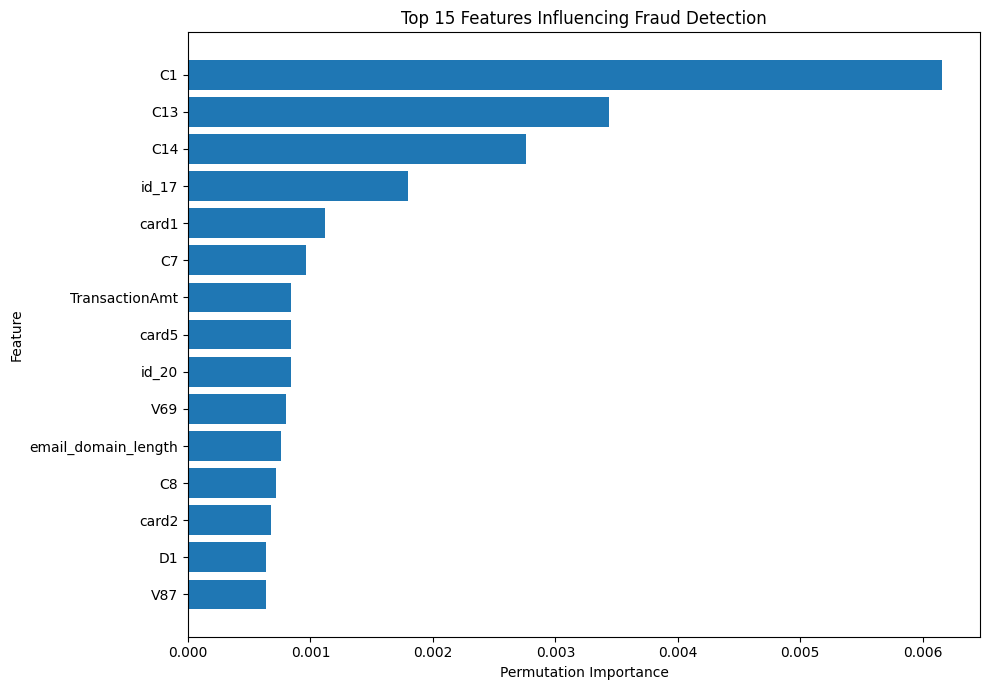

In [44]:
#visualization

import matplotlib.pyplot as plt
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"])

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Fraud Detection")
plt.tight_layout()
plt.show()

## Feature Importance — Fraud Detection

Feature importance analysis identifies the variables that contribute most to the model's frauddetection decisions. The chart presents the **top 15 features** based on permutation importance.

The results show that **C1, C13 and C14** are the most influential features followed by **id_17, card1, C7, TransactionAmt and card5**...Other important variables include **id_20, V69 and email_domain_length**.


Generating confusion matrix...


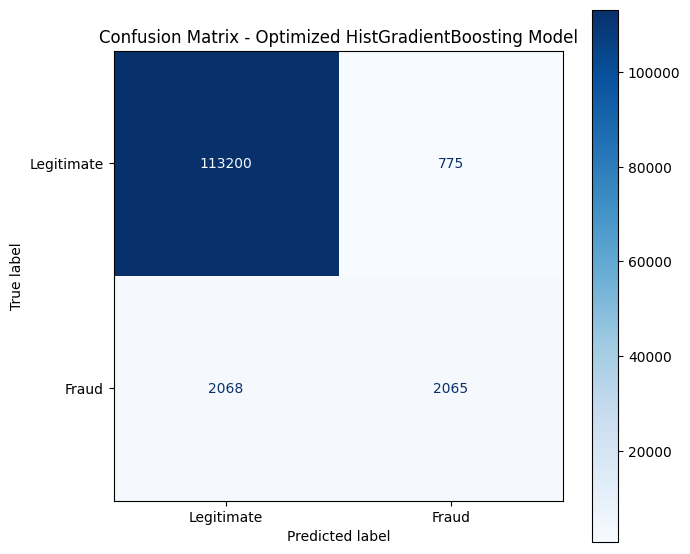

In [45]:
#confusion matrix visualization

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
print("Generating confusion matrix...")

cm = confusion_matrix(y_test, y_pred_optimized)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"])
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues")
ax.set_title("Confusion Matrix - Optimized HistGradientBoosting Model")
plt.tight_layout()
plt.show()

## Confusion Matrix — Optimized HistGradientBoosting Model

The confusion matrix provides a detailed view of the optimized HistGradientBoosting model's classification performance by showing the number of legitimate and fraudulent transactions that were correctly and incorrectly classified.

The model correctly identified **113,200 legitimate transactions** and **2,065 fraudulent transactions** while **775 legitimate transactions** were incorrectly classified as fraud and **2,068 fraudulent transactions** were incorrectly classified as legitimate.

This visualization helps assess the model's ability to distinguish fraudulent transactions from legitimate transactions and highlights the remaining false positives and false negatives.

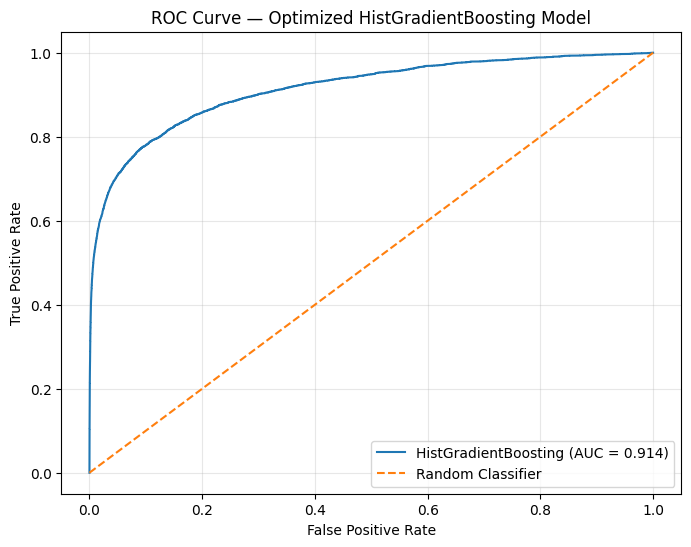

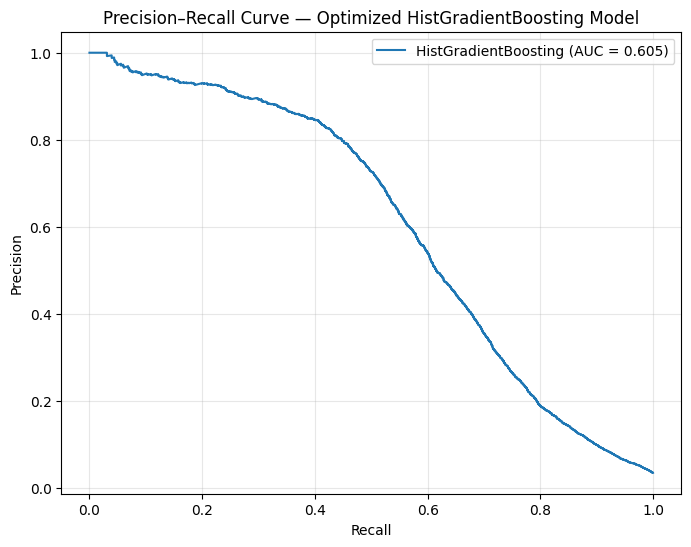

ROC-AUC: 0.914
PR-AUC: 0.605


In [47]:
from sklearn.metrics import(
    roc_curve,
    precision_recall_curve,
    auc)
import matplotlib.pyplot as plt

# Predicted probabilities for the fraud class
y_pred_proba = hgb_model.predict_proba(X_test_numeric)[:, 1]

# ROC Curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_proba)
roc_auc_hgb = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"HistGradientBoosting (AUC = {roc_auc_hgb:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Optimized HistGradientBoosting Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Precision Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_pred_proba)

pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(
    recall,
    precision,
    label=f"HistGradientBoosting (AUC = {pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Optimized HistGradientBoosting Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC: {roc_auc_hgb:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")

## ROC-AUC and Precision–Recall Curves

The ROC curve evaluates the model's ability to distinguish between legitimate and fraudulent transactions across different classification thresholds. The optimized HistGradientBoosting model achieves a **ROC-AUC of 0.914** indicating strong overall discriminatory performance.

The Precision Recall curve is particularly relevant for this fraud-detection problem because fraudulent transactions represent a much smaller proportion of the dataset. The model achieves a **PR-AUC of 0.605** demonstrating useful performance in identifying the minority fraud class while balancing precision and recall.


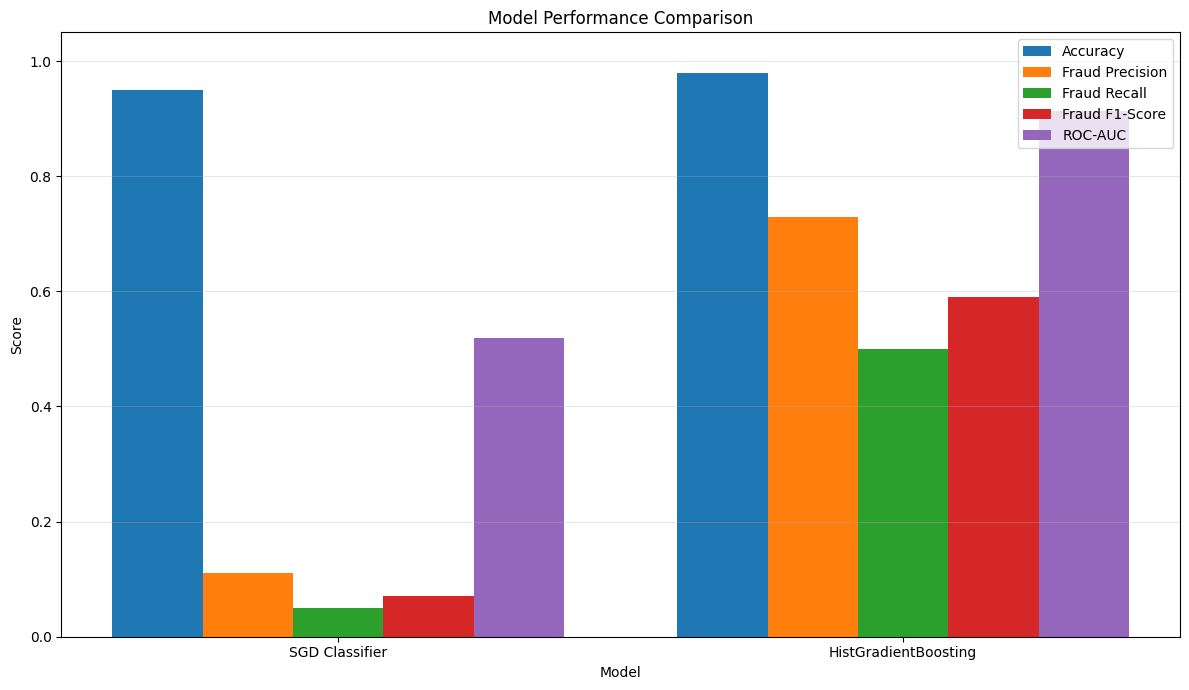

In [48]:
# Model perfomance comparison visualization
import matplotlib.pyplot as plt
import numpy as np

models = ["SGD Classifier", "HistGradientBoosting"]

accuracy = [0.95, 0.98]
fraud_precision = [0.11, 0.73]
fraud_recall = [0.05, 0.50]
fraud_f1 = [0.07, 0.59]
roc_auc = [0.519, 0.914]

x = np.arange(len(models))
width = 0.16

plt.figure(figsize=(12, 7))

plt.bar(x - 2*width, accuracy, width, label="Accuracy")
plt.bar(x - width, fraud_precision, width, label="Fraud Precision")
plt.bar(x, fraud_recall, width, label="Fraud Recall")
plt.bar(x + width, fraud_f1, width, label="Fraud F1-Score")
plt.bar(x + 2*width, roc_auc, width, label="ROC-AUC")

plt.xticks(x, models)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Model Performance Comparison")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Model Performance Comparison

The performance of the baseline SGD Classifier is compared with the optimized HistGradientBoosting model using accuracy, fraud precision, fraud recall, fraud F1-score and ROC-AUC.

The comparison highlights the improvement achieved by the HistGradientBoosting model, particularly in fraud detection. The optimized model provides substantially stronger fraud precision, recall, F1-score, and overall discriminatory performance than the baseline SGD Classifier.

## Final Model Performance and Key Findings
The optimized HistGradientBoosting model was selected as the final fraud detection model based on its superior performance compared with the baseline SGD Classifier.

### Final Model Performance

The optimized model achieved the following results:

- **Accuracy:** 98%
- **ROC-AUC:** 0.914
- **Fraud Precision:** 0.727
- **Fraud Recall:** 0.500
- **Fraud F1-Score:** 0.592

The model demonstrates strong overall classification performance and substantially improves fraud detection compared with the baseline model.

### Model Comparison

The HistGradientBoosting model outperformed the SGD Classifier across the key fraud detection metrics. In particular, the ROC-AUC increased from **0.519 to 0.914**while the fraud F1-score improved from **0.07 to 0.592**.

### Fraud Detection Performance

At the optimized classification threshold of **0.25** the model achieved a fraud precision of **72.7%** and fraud recall of **50.0%**. This threshold provides a better balance between correctly identifying fraudulent transactions and limiting false alerts.

### Key Interpretation

The results indicate that the optimized HistGradientBoosting model is considerably more effective at distinguishing fraudulent transactions from legitimate transactions than the baseline model. The model can therefore be used as the foundation for the fraud risk scoring and monitoring component of the project.

In [49]:

# DASHBOARD DATA PREPARATION

print("Preparing fraud detection dashboard data...")

# Generate fraud probabilities using the optimized model
y_pred_proba = hgb_model.predict_proba(X_test_numeric)[:, 1]

# Apply the optimized threshold
dashboard_threshold = 0.25
y_pred_dashboard = (y_pred_proba >= dashboard_threshold).astype(int)

# Create dashboard results table
dashboard_results = X_test_numeric.copy()
dashboard_results["Actual_Fraud"] = y_test.values
dashboard_results["Fraud_Probability"] = y_pred_proba
dashboard_results["Predicted_Fraud"] = y_pred_dashboard
# Create risk categories
dashboard_results["Risk_Level"] = pd.cut(
    dashboard_results["Fraud_Probability"],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk", "Critical Risk"])


print("Dashboard data prepared successfully.")
print("Dashboard dataset shape:", dashboard_results.shape)

display(dashboard_results.head())

Preparing fraud detection dashboard data...
Dashboard data prepared successfully.
Dashboard dataset shape: (118108, 246)


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,Transaction_day,Transaction_week,TransactionAmt_per_C1,TransactionAmt_per_C2,TransactionAmt_is_high,email_domain_length,Actual_Fraud,Fraud_Probability,Predicted_Fraud,Risk_Level
316078,3303078.0,7864752.0,107.949997,7585.0,553.0,150.0,226.0,264.0,87.0,2.0,...,91.0,13.0,35.983334,35.983334,1.0,7.0,0,0.003602,0,Low Risk
116888,3103888.0,2260318.0,37.021000,3154.0,408.0,185.0,224.0,299.0,87.0,1.0,...,26.0,3.0,18.510500,18.510500,0.0,11.0,0,0.007085,0,Low Risk
410211,3397211.0,10361225.0,59.000000,10057.0,225.0,150.0,224.0,181.0,87.0,1.0,...,119.0,17.0,29.500000,19.666666,0.0,7.0,0,0.008854,0,Low Risk
251027,3238027.0,5974846.0,57.950001,6207.0,355.0,150.0,166.0,143.0,87.0,3.0,...,69.0,9.0,14.487500,19.316668,0.0,9.0,0,0.002413,0,Low Risk
191265,3178265.0,4296816.0,107.949997,11207.0,361.0,150.0,226.0,325.0,87.0,5.0,...,49.0,7.0,17.991667,17.991667,1.0,7.0,0,0.003056,0,Low Risk


In [51]:

# DASHBOARD KPI SUMMARy
total_transactions = len(dashboard_results)

actual_fraud = dashboard_results["Actual_Fraud"].sum()
predicted_fraud = dashboard_results["Predicted_Fraud"].sum()

fraud_rate = actual_fraud / total_transactions
predicted_fraud_rate = predicted_fraud / total_transactions

avg_fraud_probability = dashboard_results["Fraud_Probability"].mean()

risk_counts = dashboard_results["Risk_Level"].value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk", "Critical Risk"],
    fill_value=0)

print("FRAUD DETECTION DASHBOARD KPIs")
print(f"Total Transactions: {total_transactions:,}")
print(f"Actual Fraud Cases: {actual_fraud:,}")
print(f"Predicted Fraud Cases: {predicted_fraud:,}")
print(f"Actual Fraud Rate: {fraud_rate:.2%}")
print(f"Predicted Fraud Rate: {predicted_fraud_rate:.2%}")
print(f"Average Fraud Probability: {avg_fraud_probability:.2%}")

print("\nRISK DISTRIBUTION")
print(risk_counts)

FRAUD DETECTION DASHBOARD KPIs
Total Transactions: 118,108
Actual Fraud Cases: 4,133
Predicted Fraud Cases: 2,840
Actual Fraud Rate: 3.50%
Predicted Fraud Rate: 2.40%
Average Fraud Probability: 3.38%

RISK DISTRIBUTION
Risk_Level
Low Risk         115268
Medium Risk        1088
High Risk           515
Critical Risk      1237
Name: count, dtype: int64


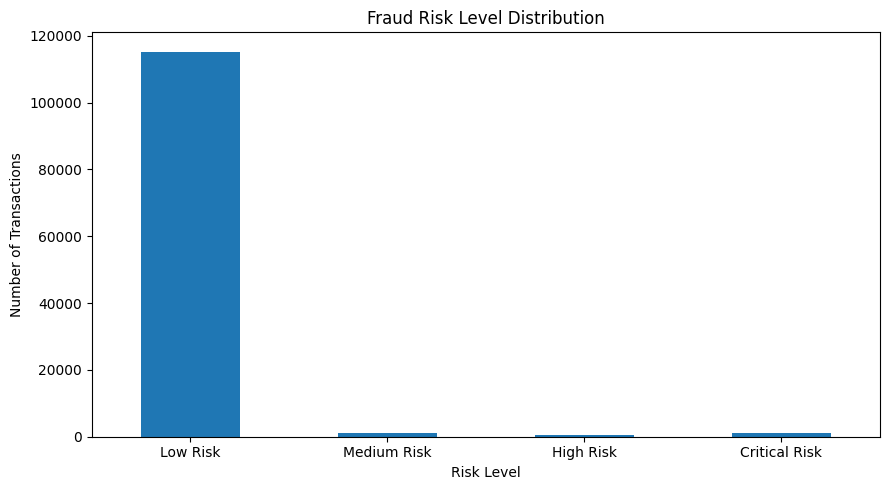

In [52]:

#risk level distribution visualization

plt.figure(figsize=(9, 5))
risk_counts.plot(kind="bar")
plt.title("Fraud Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

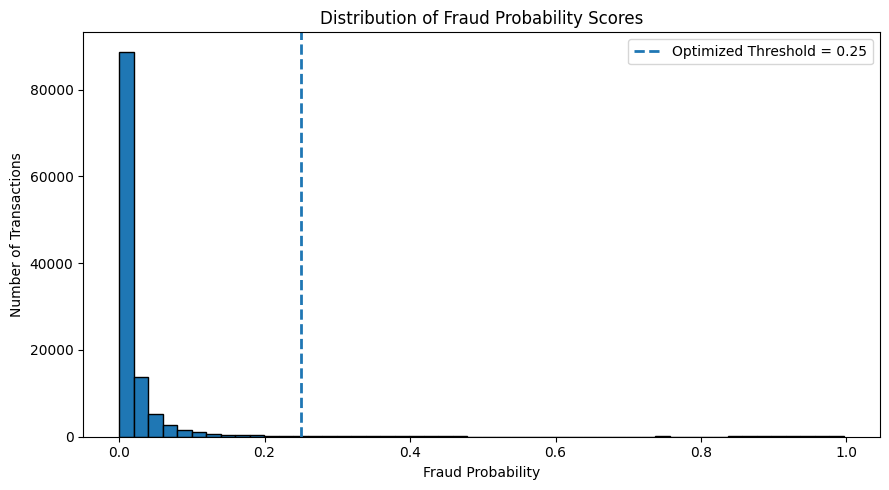

In [53]:
# fraud probablity distribution visualization
plt.figure(figsize=(9, 5))

plt.hist(
    dashboard_results["Fraud_Probability"],
    bins=50,
    edgecolor="black")

plt.axvline(
    dashboard_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Optimized Threshold = {dashboard_threshold}")

plt.title("Distribution of Fraud Probability Scores")
plt.xlabel("Fraud Probability")
plt.ylabel("Number of Transactions")
plt.legend()

plt.tight_layout()
plt.show()

 FRAUD DETECTION DASHBOARD

KEY PERFORMANCE INDICATORS
----------------------------------------
Total Transactions:       118,108
Actual Fraud Cases:       4,133
Predicted Fraud Cases:    2,840
Actual Fraud Rate:        3.50%
Predicted Fraud Rate:     2.40%
Average Fraud Probability:3.38%

RISK DISTRIBUTION
----------------------------------------
Risk_Level
Low Risk         115268
Medium Risk        1088
High Risk           515
Critical Risk      1237
Name: count, dtype: int64


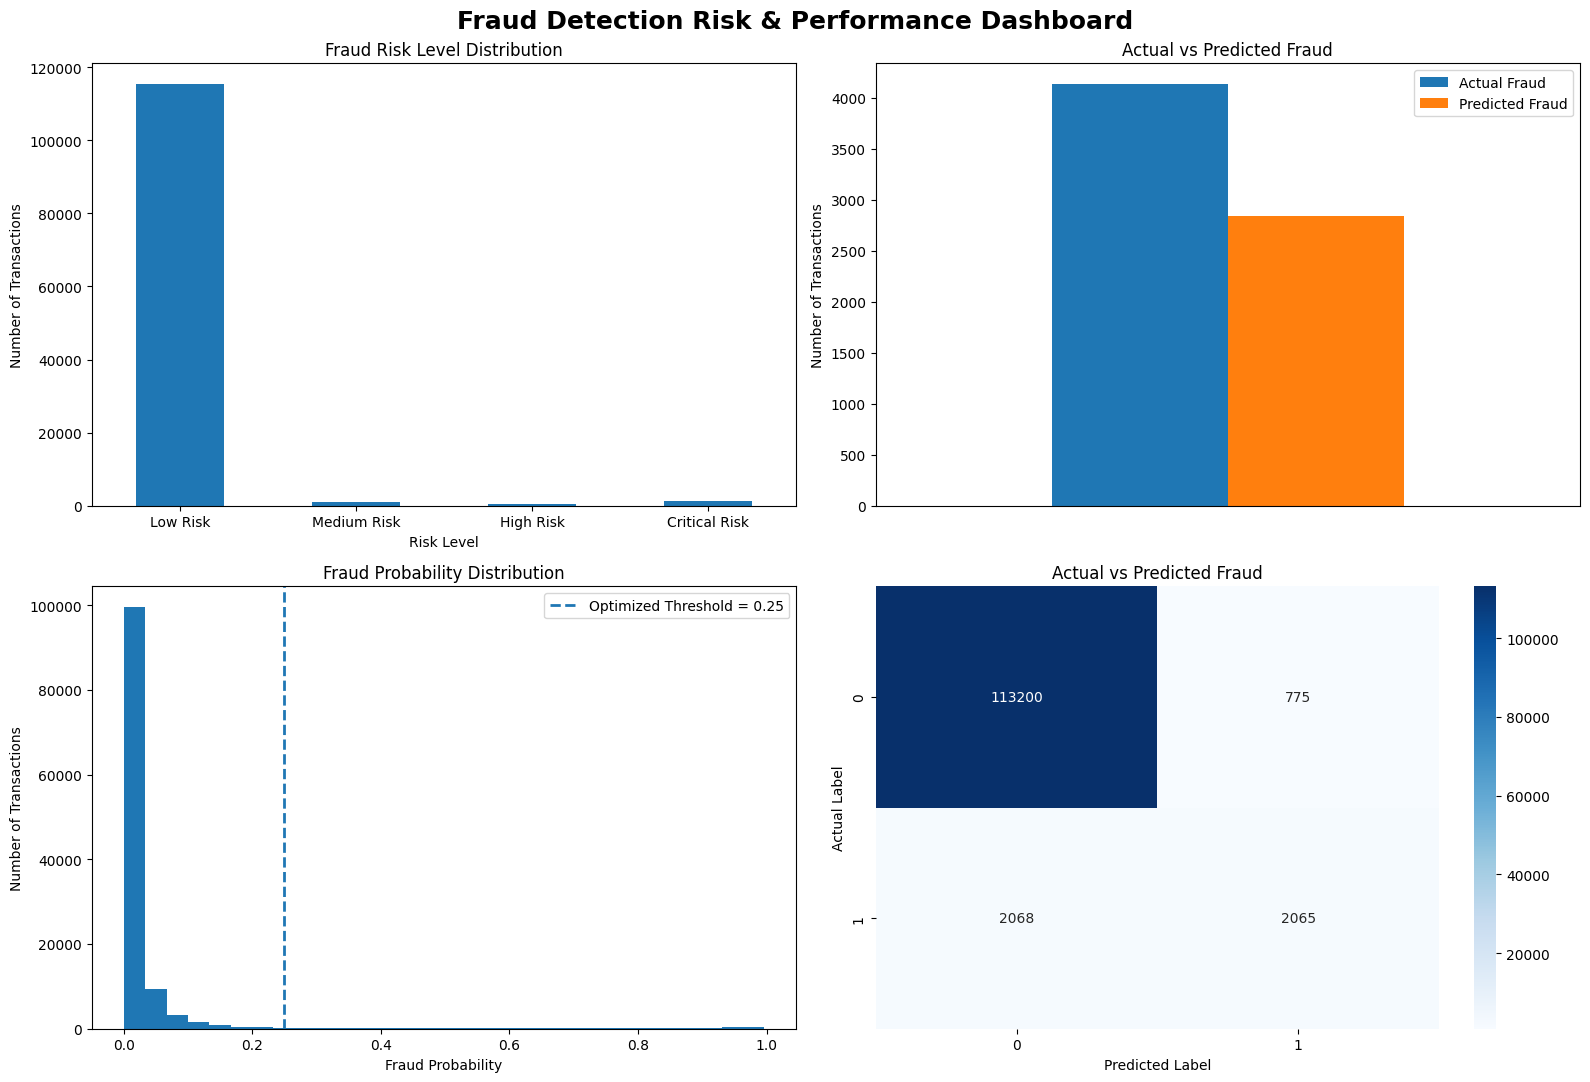

In [54]:

# FRAUD DETECTION DASHBOARD

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print(" FRAUD DETECTION DASHBOARD")

# 1. KPI SUMMARY

total_transactions = len(dashboard_results)
actual_fraud = dashboard_results["Actual_Fraud"].sum()
predicted_fraud = dashboard_results["Predicted_Fraud"].sum()

actual_fraud_rate = actual_fraud / total_transactions
predicted_fraud_rate = predicted_fraud / total_transactions

avg_fraud_probability = dashboard_results["Fraud_Probability"].mean()

print("\nKEY PERFORMANCE INDICATORS")
print("-" * 40)
print(f"Total Transactions:       {total_transactions:,}")
print(f"Actual Fraud Cases:       {actual_fraud:,}")
print(f"Predicted Fraud Cases:    {predicted_fraud:,}")
print(f"Actual Fraud Rate:        {actual_fraud_rate:.2%}")
print(f"Predicted Fraud Rate:     {predicted_fraud_rate:.2%}")
print(f"Average Fraud Probability:{avg_fraud_probability:.2%}")

# 2. RISK DISTRIBUTION
risk_distribution = (
    dashboard_results["Risk_Level"]
    .value_counts()
    .reindex(["Low Risk", "Medium Risk", "High Risk", "Critical Risk"])
    .fillna(0))
print("\nRISK DISTRIBUTION")
print("-" * 40)
print(risk_distribution)
# 3. DASHBOARD VISUALIZATION
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
# Risk distribution
risk_distribution.plot(
    kind="bar",
    ax=axes[0, 0])

axes[0, 0].set_title("Fraud Risk Level Distribution")
axes[0, 0].set_xlabel("Risk Level")
axes[0, 0].set_ylabel("Number of Transactions")
axes[0, 0].tick_params(axis="x", rotation=0)
# Actual vs predicted fraud
comparison = pd.DataFrame({
    "Actual Fraud": [actual_fraud],
    "Predicted Fraud": [predicted_fraud]})
comparison.plot(
    kind="bar",
    ax=axes[0, 1])

axes[0, 1].set_title("Actual vs Predicted Fraud")
axes[0, 1].set_ylabel("Number of Transactions")
axes[0, 1].set_xticks([])
axes[0, 1].legend()

# Fraud probability distribution
axes[1, 0].hist(
    dashboard_results["Fraud_Probability"],
    bins=30)
axes[1, 0].axvline(
    x=0.25,
    linestyle="--",
    linewidth=2,
    label="Optimized Threshold = 0.25")

axes[1, 0].set_title("Fraud Probability Distribution")
axes[1, 0].set_xlabel("Fraud Probability")
axes[1, 0].set_ylabel("Number of Transactions")
axes[1, 0].legend()

# Actual fraud vs predicted fraud
confusion = pd.crosstab(
    dashboard_results["Actual_Fraud"],
    dashboard_results["Predicted_Fraud"])
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1, 1])

axes[1, 1].set_title("Actual vs Predicted Fraud")
axes[1, 1].set_xlabel("Predicted Label")
axes[1, 1].set_ylabel("Actual Label")

plt.suptitle(
    "Fraud Detection Risk & Performance Dashboard",
    fontsize=18,
    fontweight="bold")

plt.tight_layout()
plt.show()

# 💳 Fraud Detection Risk & Performance Dashboard

## Overview
This dashboard presents the performance of the optimized **HistGradientBoosting fraud detection model** and provides an overview of transactionlevel fraud risk.

### Key Performance Indicators

| Metric | Value |
|---|---:|
| Total Transactions | 118,108 |
| Actual Fraud Cases | 4,133 |
| Predicted Fraud Cases | 2,840 |
| Actual Fraud Rate | 3.50% |
| Predicted Fraud Rate | 2.40% |
| Average Fraud Probability | 3.38% |
| ROC-AUC | 0.914 |
| Fraud Precision | 0.727 |
| Fraud Recall | 0.500 |
| Fraud F1-Score | 0.592 |

## Risk Classification

Transactions are classified into four risk categories based on their predicted fraud probability:

- 🟢 **Low Risk:** 0–25%
- 🟡 **Medium Risk:** 25–50%
- 🟠 **High Risk:** 50–75%
- 🔴 **Critical Risk:** 75–100%

## Dashboard Components

### 1. Fraud Risk Level Distribution
Shows the distribution of transactions across the four fraudrisk categories.

### 2. Actual vs Predicted Fraud
Compares the number of actual fraudulent transactions with those identified by the optimized model.

### 3. Fraud Probability Distribution
Displays the distribution of predicted fraud probabilities and highlights the optimized classification threshold of **0.25**.

### 4. Confusion Matrix
Shows the model's classification performance across legitimate and fraudulent transactions.

## Key Model Findings

The optimized HistGradientBoosting model achieved a **ROC-AUC of 0.914** indicating strong discrimination between legitimate and fraudulent transactions.

At the optimized threshold of **0.25**the model achieved:

- **Precision:** 72.7%
- **Recall:** 50.0%
- **F1-Score:** 59.2%

The results demonstrate that the model can identify a substantial proportion of fraudulent transactions while maintaining relatively high precision.

## Business Interpretation

The dashboard can support fraudmonitoring teams by helping them:

- Identify transactions with elevated fraud probability.
- Prioritize **High Risk** and **Critical Risk** transactions for investigation.
- Monitor the difference between actual and model detected fraud.
- Evaluate model performance using operational fraud metrics.
- Use risk probabilities to support transactionreview decisions.

## 7. Model Interpretation and Business Insights

The optimized HistGradientBoosting model demonstrates strong overall discrimination between legitimate and fraudulent transactions, achieving a ROC-AUC score of 0.914. However because fraud is a highly imbalanced classification problem accuracy alone is not sufficient to evaluate model performance.

The optimized model achieved a fraud precision of 0.727, recall of 0.500 and F1-score of 0.592. This indicates that the model identifies a meaningful proportion of fraudulent transactions while maintaining relatively high precision among transactions flagged as fraud.

### Key Findings

- **ROC-AUC = 0.914:** The model has strong ability to distinguish fraudulent transactions from legitimate transactions.
- **Fraud Precision = 72.7%:** Approximately 73% of transactions predicted as fraudulent were actually fraudulent.
- **Fraud Recall = 50.0%:** The model detected half of the fraudulent transactions in the test set.
- **Fraud F1-Score = 59.2%:** The F1-score reflects the balance between precision and recall for the minority fraud class.
- **Optimized Threshold = 0.25:** A lower classification threshold was used to improve fraud detection sensitivity compared with the default 0.50 threshold.

### Feature Importance

Permutation importance analysis identified the features with the greatest contribution to model performance. The most influential variables included:

1. "C1"
2. `C13`
3. `C14`
4. `id_17`
5. `card1`
6. `C7`
7. `TransactionAmt`
8. `card5`
9. `id_20`
10. `V69`
11. `email_domain_length`


### Fraud Risk Distribution

Transactions were grouped into four risk categories based on predicted fraud probability:

- **Low Risk**
- **Medium Risk**
- **High Risk**
- **Critical Risk**

The majority of transactions were classified as Low Risk while a much smaller proportion fell into the medium, high and critical risk categories. This distribution can support a riskbased fraud monitoring strategy in which higherrisk transactions receive greater scrutiny.

### Business Implications

The model can support financial institutions or payment platforms by prioritizing suspicious transactions for investigation. Rather than treating every transaction equally fraud teams can focus their resources on transactions with elevated predicted fraud probabilities.

The results demonstrate the tradeoff between detecting more fraud and generating false alerts. Increasing fraud recall may identify more fraudulent transactions but can also increase the number of legitimate transactions incorrectly flagged for investigation.

### Recommendations

1. Use the model as a **risk-ranking and investigation-support tool** rather than relying on it as the sole decision-maker.
2. Prioritize **High Risk and Critical Risk** transactions for additional review.
3. Monitor false negatives because undetected fraud represents potential financial loss.
4. Monitor false positives to avoid unnecessary customer friction and investigation costs.
5. Periodically retrain and evaluate the model as transaction patterns and fraud tactics change.
6. Continue monitoring precision, recall, F1-score and ROC-AUC rather than relying on accuracy alone.


## 8. Conclusion and Recommendations

### Conclusion

This project focused on using machine learning to identify potentially fraudulent financial transactions and assign different levels of fraud risk.

The optimized HistGradientBoosting model performed well achieving a **ROC-AUC of 0.914**. Using the optimized threshold of **0.25**, the model achieved **72.7% precision**, **50.0% recall** and an **F1-score of 59.2%** for fraud detection.

The analysis shows that some transaction, card and other behavioral features played a bigger role in distinguishing fraudulent transactions from legitimate ones. The model's fraud probabilities were used to group transactions into **low,medium,high and critical risk** categories.

### Recommendations

The model could be used to help fraud teams identify transactions that may need closer attention.

- **High and Critical Risk transactions** should be prioritized for further review.
- Fraud probability can be used to rank transactions according to their level of risk.
- False negatives should be monitored closely because they represent fraudulent transactions that the model failed to identify.
- False positives should also be monitored to avoid unnecessarily flagging legitimate customers.
- The model should be retrained and evaluated regularly as fraud patterns change over time.
- In a real world settingth e model should work alongside existing fraud rules and human review rather than being used as the only decision-making system.

### Overall

The results show that machine learning can be useful for supporting fraud detection and helping financial institutions focus their attention on higher risk transactions...With testing, monitoring and integration with realtime transaction systems this approach could form part of a broader fraud risk management solution.

# Project Outcome

The final model provides a practical approach for identifying potentially fraudulent transactions and prioritizing higher-risk cases for further investigation. The results show how machine learning can support fraud monitoring using transaction-level data.